In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# load files
runner_url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-10-26/ultra_rankings.csv'
race_url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2021/2021-10-26/race.csv'

runner_stats = pd.read_csv(runner_url)
race_stats = pd.read_csv(race_url)

print('Runner table (rows, columns):', runner_stats.shape)
print('Race table (rows, columns):', race_stats.shape)

# five rows from each original table
display(runner_stats.head())
display(race_stats.head())
race_stats.groupby('country').size().sort_values(ascending=False).shape
race_stats.groupby('city').size().sort_values(ascending=False).shape

Runner table (rows, columns): (137803, 8)
Race table (rows, columns): (1207, 13)


,race_year_id,rank,runner,time,age,gender,nationality,time_in_seconds
0,68140,1.0,VERHEUL Jasper,26H 35M 25S,30,M,GBR,95725.0
1,68140,2.0,MOULDING JON,27H 0M 29S,43,M,GBR,97229.0
2,68140,3.0,RICHARDSON Phill,28H 49M 7S,38,M,GBR,103747.0
3,68140,4.0,DYSON Fiona,30H 53M 37S,55,W,GBR,111217.0
4,68140,5.0,FRONTERAS Karen,32H 46M 21S,48,W,GBR,117981.0


,race_year_id,event,race,city,country,date,start_time,participation,distance,elevation_gain,elevation_loss,aid_stations,participants
0,68140,Peak District Ultras,Millstone 100,Castleton,United Kingdom,2021-09-03,19:00:00,solo,166.9,4520,-4520,10,150
1,72496,UTMB®,UTMB®,Chamonix,France,2021-08-27,17:00:00,Solo,170.7,9930,-9930,11,2300
2,69855,Grand Raid des Pyrénées,Ultra Tour 160,vielle-Aure,France,2021-08-20,05:00:00,solo,167.0,9980,-9980,13,600
3,67856,Persenk Ultra,PERSENK ULTRA,Asenovgrad,Bulgaria,2021-08-20,18:00:00,solo,164.0,7490,-7500,13,150
4,70469,Runfire Salt Lake Ultra,100 Mile,ulukisla,Turkey,2021-08-20,18:00:00,solo,159.9,100,-100,12,0


(308,)

In [9]:
# display the number missing in every column
print('Missing values in the original runner table:')
display(runner_stats.isna().sum())
print('Missing values in the original race table:')
display(race_stats.isna().sum())

# count identical rows before removing anything
print('Exact duplicate runner rows:', runner_stats.duplicated().sum())
print('Exact duplicate race rows:', race_stats.duplicated().sum())

# ranges

display(runner_stats.select_dtypes(include='number').agg(['min', 'max']).T)
display(race_stats.select_dtypes(include='number').agg(['min', 'max']).T)

Missing values in the original runner table:


,0
race_year_id,0
rank,17791
runner,0
time,17791
age,0
gender,30
nationality,0
time_in_seconds,17791


Missing values in the original race table:


,0
race_year_id,0
event,0
race,0
city,172
country,4
date,0
start_time,0
participation,0
distance,0
elevation_gain,0


Exact duplicate runner rows: 36
Exact duplicate race rows: 0


,min,max
race_year_id,2320.0,72496.0
rank,1.0,1962.0
age,0.0,133.0
time_in_seconds,3600.0,296806.0


,min,max
race_year_id,2320.0,72496.0
distance,0.0,179.1
elevation_gain,0.0,14430.0
elevation_loss,-14440.0,0.0
aid_stations,0.0,56.0
participants,0.0,2900.0


#Cleaning

## Identifying zero and erroneous values

In [10]:
# check measurements that could contain placeholders
print('Race editions with zero distance:', (race_stats['distance'] == 0).sum())
print('Race editions with zero elevation gain:', (race_stats['elevation_gain'] == 0).sum())
print('Race editions with zero participants:', (race_stats['participants'] == 0).sum())
print('Race editions with zero aid stations:', (race_stats['aid_stations'] == 0).sum())
print('Results missing finish time:', runner_stats['time_in_seconds'].isna().sum())

# flagging suspicous ages without deleting those runners
age_needs_review = (runner_stats['age'] <= 0) | (runner_stats['age'] > 100)
print('Results with age zero or over 100:', age_needs_review.sum())

# trying to distinguish missing distance placeholders from shorter courses
short_courses = race_stats[race_stats['distance'] > 0]
short_courses = short_courses[short_courses['distance'] < 42.195]
print('Positive-distance courses shorter than a marathon:', len(short_courses))
display(short_courses[['race_year_id', 'race', 'distance']])

Race editions with zero distance: 74
Race editions with zero elevation gain: 74
Race editions with zero participants: 582
Race editions with zero aid stations: 379
Results missing finish time: 17791
Results with age zero or over 100: 1404
Positive-distance courses shorter than a marathon: 1


,race_year_id,race,distance
110,54013,P'tiot Sparnatrail,33.3


## Removing duplicates, erroneous values, and merging the datasets

In [11]:
#removing only identical rows, keeping the originals unchanged
runner_stats_clean = runner_stats.drop_duplicates().copy()
race_stats_clean = race_stats.drop_duplicates().copy()
print('Runner rows before removing duplicates:', len(runner_stats))
print('Runner rows after removing duplicates:', len(runner_stats_clean))
print('Race rows before removing duplicates:', len(race_stats))
print('Race rows after removing duplicates:', len(race_stats_clean))

# Why are we creating course_data separately from the cleaned_df?
course_data = race_stats_clean[race_stats_clean['distance'] > 0].copy()
print('Race editions after excluding nonpositive distance:', len(course_data))
course_data = course_data[course_data['elevation_gain'] > 0].copy()
print('Race editions after excluding nonpositive elevation gain:', len(course_data))
course_data['climb_per_km'] = course_data['elevation_gain'] / course_data['distance']

# join using cleaned copies
clean_df = runner_stats_clean.merge(
    course_data,
    on='race_year_id',
    how='left',
    validate='many_to_one',
    indicator=True
)

print('Rows after the cleaned join:', len(clean_df))
print('Unmatched rows after the cleaned join:', (clean_df['_merge'] == 'left_only').sum())
# missing times do not necessarily establish DNF status
#show the row count after each exclusion
zeros_df = clean_df[clean_df['time_in_seconds'].notna()]
print('After excluding missing finish times:', len(zeros_df))
zeros_df = clean_df[clean_df['time_in_seconds'] > 0]
print('After excluding nonpositive finish times:', len(zeros_df))
zeros_df = clean_df[clean_df['distance'] > 0]
print('After excluding nonpositive distance:', len(zeros_df))
zeros_df = clean_df[clean_df['elevation_gain'] > 0]
print('After excluding nonpositive elevation gain:', len(zeros_df))

Runner rows before removing duplicates: 137803
Runner rows after removing duplicates: 137767
Race rows before removing duplicates: 1207
Race rows after removing duplicates: 1207
Race editions after excluding nonpositive distance: 1133
Race editions after excluding nonpositive elevation gain: 1133
Rows after the cleaned join: 137767
Unmatched rows after the cleaned join: 7663
After excluding missing finish times: 119986
After excluding nonpositive finish times: 119986
After excluding nonpositive distance: 130104
After excluding nonpositive elevation gain: 130104


## Feature Engineering

In [13]:
clean_df['finish_hours'] = clean_df['time_in_seconds'] / 3600
# calculating climb per km gain to help estimate difficulty
clean_df['climb_per_km'] = clean_df['elevation_gain'] / clean_df['distance']
print('Race editions represented by the remaining results:', clean_df['race_year_id'].nunique())

# convert km to miles for the plot
course_data['distance_miles'] = course_data['distance'] / 1.609344

clean_df.head()

Race editions represented by the remaining results: 1207


,race_year_id,rank,runner,time,age,gender,nationality,time_in_seconds,event,race,...,start_time,participation,distance,elevation_gain,elevation_loss,aid_stations,participants,climb_per_km,_merge,finish_hours
0,68140,1.0,VERHEUL Jasper,26H 35M 25S,30,M,GBR,95725.0,Peak District Ultras,Millstone 100,...,19:00:00,solo,166.9,4520.0,-4520.0,10.0,150.0,27.082085,both,26.590278
1,68140,2.0,MOULDING JON,27H 0M 29S,43,M,GBR,97229.0,Peak District Ultras,Millstone 100,...,19:00:00,solo,166.9,4520.0,-4520.0,10.0,150.0,27.082085,both,27.008056
2,68140,3.0,RICHARDSON Phill,28H 49M 7S,38,M,GBR,103747.0,Peak District Ultras,Millstone 100,...,19:00:00,solo,166.9,4520.0,-4520.0,10.0,150.0,27.082085,both,28.818611
3,68140,4.0,DYSON Fiona,30H 53M 37S,55,W,GBR,111217.0,Peak District Ultras,Millstone 100,...,19:00:00,solo,166.9,4520.0,-4520.0,10.0,150.0,27.082085,both,30.893611
4,68140,5.0,FRONTERAS Karen,32H 46M 21S,48,W,GBR,117981.0,Peak District Ultras,Millstone 100,...,19:00:00,solo,166.9,4520.0,-4520.0,10.0,150.0,27.082085,both,32.772500


##Flagging potential data errors

In [14]:
# flagging these times but keeping them until we investigate
short_times = clean_df[clean_df['finish_hours'] < 10]
short_times = short_times[short_times['distance'] >= 140]
print('Results under 10 hours on courses of at least 140 km:', len(short_times))
display(short_times[['race_year_id', 'race', 'distance', 'time', 'finish_hours']])


Results under 10 hours on courses of at least 140 km: 2


,race_year_id,race,distance,time,finish_hours
5303,69065,24 LOOPS,160.7,4H 12M 54S,4.215
43088,38825,160 km,168.6,1H 0M 0S,1.000


##Distributions of Elevation and Distance

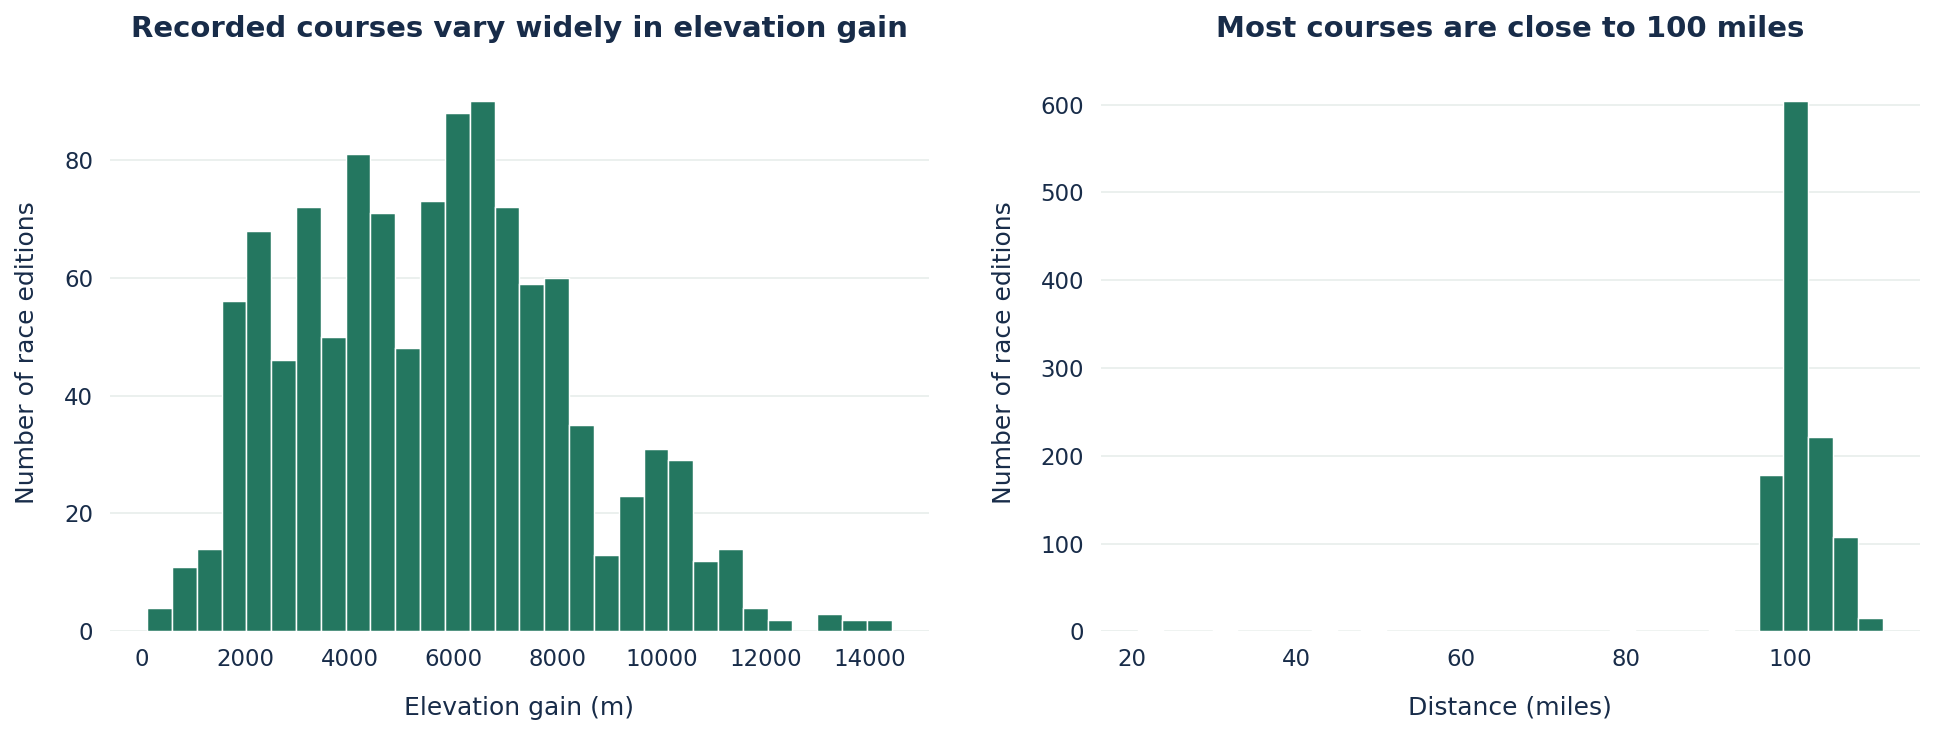

Race editions in these plots: 1133
Median recorded distance before exclusions (miles): 100.4
Median distance in the plotted sample (miles): 100.5
Median elevation gain in the plotted sample (m): 5535.0
Minimum and maximum plotted elevation gain (m): 100 14430


In [ ]:
green = '#247760'
navy = '#182C49'

# using course data (not the merged clean_df runner data) to create 2 histograms for elevation and distance
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 5), dpi=150)

axes[0].hist(course_data['elevation_gain'], bins=30, color=green, edgecolor='white', linewidth=0.7)
axes[0].set_title('Recorded courses vary widely in elevation gain', color=navy, fontsize=14, fontweight='bold', pad=18)
axes[0].set_xlabel('Elevation gain (m)')
axes[0].set_ylabel('Number of race editions')

axes[1].hist(course_data['distance_miles'], bins=30, color=green, edgecolor='white', linewidth=0.7)
axes[1].set_title('Most courses are close to 100 miles', color=navy, fontsize=14, fontweight='bold', pad=18)
axes[1].set_xlabel('Distance (miles)')
axes[1].set_ylabel('Number of race editions')

# update style
fig.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#E8EDEB', linewidth=0.8)
    ax.set_frame_on(False)
    ax.tick_params(colors=navy, labelsize=11, length=0, pad=8)
    ax.xaxis.label.set_color(navy)
    ax.yaxis.label.set_color(navy)
    ax.xaxis.label.set_fontsize(12)
    ax.yaxis.label.set_fontsize(12)
    ax.xaxis.labelpad = 12
    ax.yaxis.labelpad = 12

plt.tight_layout(w_pad=3)
plt.show()

print('Race editions in these plots:', len(course_data))
print('Median recorded distance before exclusions (miles):', round(race_stats['distance'].median() / 1.609344, 1))
print('Median distance in the plotted sample (miles):', round(course_data['distance_miles'].median(), 1))
print('Median elevation gain in the plotted sample (m):', course_data['elevation_gain'].median())
print('Minimum and maximum plotted elevation gain (m):', course_data['elevation_gain'].min(), course_data['elevation_gain'].max())

##Elevation Data

In [ ]:
# I will be looking for a dataset so we can gather elevation data to assist with assessing course difficulty
# -Norm

##Weather Data (WIP)

#Questions and Analysis

##1. Does elevation gain improve time predictions beyond distance alone? (good to write)

##2. Do more mountainous courses have wider finishing time spreads? (pending Elevation & Weather data)

##3. Does the women’s/men’s time gap vary with course difficulty? (good to write)

##4. Are races getting faster and more closely contested over time? (good to write)

#Models (pending Elevation & Weather data + Questions and Analysis completed)